In [1]:
%load_ext autoreload
%autoreload 2
import isautilities as isau
import modelsCNN as models
import numpy as np
import fmatoolbox as fma
import torch
import sklearn as sk
import joblib
import pathlib
froot = pathlib.Path().cwd() / 'Results' / 'UnitBinaryPool'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
do_save = False

In [20]:
print(torch.cuda.get_device_name(0))

props = torch.cuda.get_device_properties(0)
print(f"Total VRAM: {props.total_memory / 1024**3:.1f} GB")

print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print(f'{[a / 1024**3 for a in torch.cuda.mem_get_info()]}')

NVIDIA RTX 5000 Ada Generation
Total VRAM: 31.5 GB
Allocated: 0.02 GB
Reserved:  0.18 GB
[14.08941650390625, 31.47540283203125]


In [2]:
def _couplData(session,regs,lim=None,n=None,return_t=None):
    # load spiking data around ripple peaks for a session
    if lim is None: lim = (-0.4,0.4)
    if n is None: n = 25

    # load data
    R = fma.regions.regions(session,states='sws',events='InfraSlowRhythm/infraslowaval')
    events, is_coupl, is_isa = isau.loadHpcPfcEvents(session,names=['ripples','down','spindles'],regions=R,
                                                     coupl=True,wait=0.5,isa=R.eventIntervals('slownr'),sleep=R.eventIntervals('sws'))

    # spikes around ripples
    spikes = R.spikes(regs=regs)
    data, t, _ = fma.analysis.PETH(spikes[:,0],events['ripples'],limits=lim,bin=0.01,groups=spikes[:,1],g_range=R.units(regs=regs)) # (event, time, unit)
    n_events, n_times, n_units = data.shape
    data = data.reshape((-1,n_units)) # (event * time, unit)

    pca = sk.decomposition.PCA(n_components=n)
    data = pca.fit_transform(data)

    data = data.reshape((n_events,n_times,-1)) # (event, time, pcs)
    data = np.permute_dims(data,(0,2,1)) # (event, pcs, time)

    if return_t:
        return data, is_coupl['ripples'], t
    return data, is_coupl['ripples']

In [6]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][9]
print(session)
X, y, t = _couplData(session,'pfc',return_t=True)

/mnt/hubel-data-131/perceval/Rat003_20231224/Rat003_20231224.xml


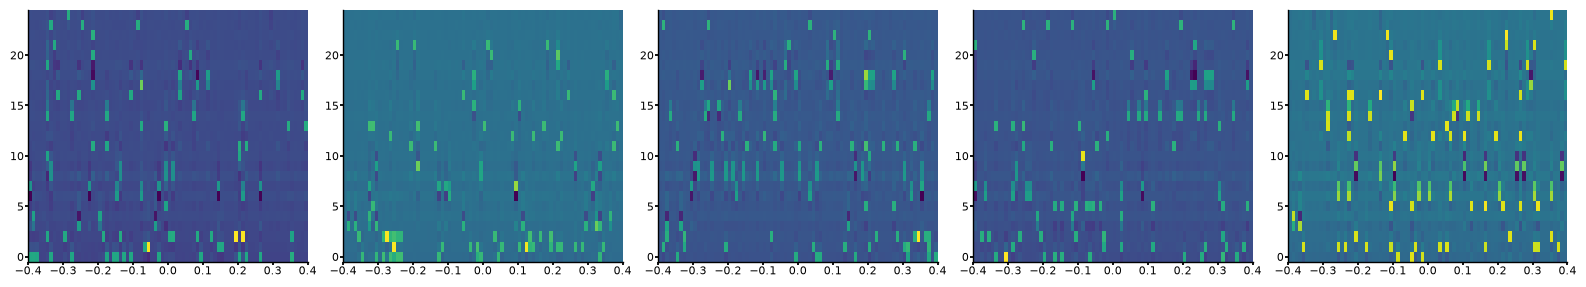

In [7]:
# see examples
plot_idx = np.arange(5) * 5 + 8
fig, ax = fma.plotting.makeFigure(n=(1,len(plot_idx)),size=(40,7))
for i, p in enumerate(plot_idx):
    fma.plotting.plotColorMap(X[p],x=t,ax=ax[i])

run batch

In [3]:
def couplDataset(sessions,regs,lim=None):
    # load and concatenate data from multiple sessions
    X, y = fma.data.runBatch(batch_file,_couplData,kwargs={'regs': regs, 'lim': lim},parallel=True,sessions=sessions,verbose=False)
    group = np.concatenate([np.full(len(x),i,dtype=int) for i, x in enumerate(X) if x is not None])
    X = np.concatenate([x for x in X if x is not None])
    y = np.concatenate([_y for _y in y if _y is not None])
    return X, y, group

def learningCurveLOO(groups,rnd_seed=None):
    # get shuffled group ids per fold of a LeaveOneOut CV
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(rnd_seed)
    out = []
    for g in unique_groups:
        gr = unique_groups[unique_groups!=g]
        rng.shuffle(gr)
        out.append(gr)
    return out

def couplingCNN(sessions,regs,lim=(-0.4,0.4),model="CNN1d",train_sizes=None,fname=None,rnd_seed=None):

    # configure GPU use
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f'device: {device}')

    X, y, group = couplDataset(sessions,regs,lim=lim)
    print(f'target: {y.mean()}')
    X = torch.tensor(X,dtype=torch.float32)
    y = torch.tensor(y.astype(float),dtype=torch.float32)

    mod = model # store model name
    kf = sk.model_selection.LeaveOneGroupOut().split(X,y,group)
    train_groups = learningCurveLOO(group,rnd_seed=rnd_seed)
    n_folds = len(train_groups)
    train_sizes = [n_folds - 1] if train_sizes is None else np.array(train_sizes,ndmin=1)
    train_sizes = np.clip(train_sizes,1,n_folds-1)

    n_epochs = 50
    n_train = len(train_sizes)
    train_losses = np.full((n_folds,n_epochs),np.nan) # only for last train size
    val_losses = np.full((n_folds,n_epochs),np.nan) # only for last train size
    train_auc = np.full((n_folds,n_train,n_epochs),np.nan)
    test_auc = np.full((n_folds,n_train,n_epochs),np.nan)
    def score(a,b): return sk.metrics.average_precision_score(np.concatenate(a), np.concatenate(b))

    print("fold  -  validation loss")
    for fold, (train_idx, val_idx) in enumerate(kf):
        print(f"  {fold+1}   -",end="")

        for i, n in enumerate(train_sizes):
            this_train_idx = train_idx[ np.isin(group[train_idx],train_groups[fold][:n]) ]

            # split into train and validation sets
            X_train = X[this_train_idx]
            y_train = y[this_train_idx]
            X_val = X[val_idx]
            y_val = y[val_idx]

            # normalize
            m = X_train.mean(dim=(0,2),keepdim=True)
            s = X_train.std(dim=(0,2),keepdim=True)
            s = torch.clamp(s,min=1e-8)
            X_train = (X_train - m) / s
            X_val = (X_val - m) / s

            # data loaders
            train_ds = torch.utils.data.TensorDataset(X_train,y_train)
            val_ds = torch.utils.data.TensorDataset(X_val,y_val)
            train_loader = torch.utils.data.DataLoader(train_ds,batch_size=1024,shuffle=True)
            val_loader = torch.utils.data.DataLoader(val_ds,batch_size=1024,shuffle=False)

            # define / reset model
            model = models.loadModel(mod,n_features=X.shape[1]).to(device)
            optimizer = torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-3) # weight_decay against overfitting
            criterion = torch.nn.BCEWithLogitsLoss()
            #pos_weight = (y_train==0).sum() / (y_train==1).sum()
            #float(pos_weight>100) and print(f' pw:{pos_weight.numpy():.2f}!',end='')
            #criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

            # track per epoch histories
            this_train_losses = [] # for this n, one value per epoch
            this_val_losses = []
            for epoch in range(n_epochs):
                # 1. train
                model.train()
                this_train_losses.append([])
                for xb, yb in train_loader:
                    optimizer.zero_grad()
                    logits = model(xb.to(device)).squeeze(-1)
                    loss = criterion(logits,yb.to(device))
                    loss.backward()
                    optimizer.step()
                    this_train_losses[-1].append(loss.item())
                this_train_losses[-1] = np.mean(this_train_losses[-1])
                # 2. validation
                model.eval()
                this_val_losses.append([])
                train_true = []
                train_prob = []
                val_true = []
                val_prob = []
                with torch.no_grad():
                    # train scores
                    for xb, yb in train_loader:
                        logits = model(xb.to(device)).squeeze(-1)
                        prob = torch.sigmoid(logits)
                        train_true.append(yb.numpy())
                        train_prob.append(prob.cpu().numpy())
                    # test set validation
                    for xb, yb in val_loader:
                        yb = yb.to(device)
                        logits = model(xb.to(device)).squeeze(-1)
                        loss = criterion(logits,yb)
                        this_val_losses[-1].append(loss.item())
                        prob = torch.sigmoid(logits)
                        val_true.append(yb.cpu().numpy())
                        val_prob.append(prob.cpu().numpy())
                this_val_losses[-1] = np.mean(this_val_losses[-1])
                train_auc[fold,i,epoch] = score(train_true,train_prob)
                test_auc[fold,i,epoch] = score(val_true,val_prob)

        # keep only losses of last n per fold
        train_losses[fold] = this_train_losses
        val_losses[fold] = this_val_losses
        print(f"  {this_val_losses[-1]:.4f}")

        results = {'train_sizes': np.asarray(train_sizes),
                   'train_losses': np.array(train_losses),
                   'val_losses': np.array(val_losses),
                   'train_scores': np.array(train_auc),
                   'test_scores': np.array(test_auc)}
        name = regs if (isinstance(regs,str) or len(regs)) == 1 else '_'.join(regs)
        if fname is not None: name += '_' + fname
        joblib.dump(results, froot / f"{mod}_l[{lim[0]},{lim[1]}]_{name}.joblib")

    return results

In [4]:
sessions = np.arange(0,34,2)
train_sizes = [4,8,12,16]
for r in ['pfc','hpc','nr']:
    for l in [(-0.4,0.4), (-0.4,0)]:
        CNN_cv = couplingCNN(sessions,regs=r,model='CNN1D_noregu',lim=l,train_sizes=train_sizes,rnd_seed=42)

device: cuda
Error in session /mnt/hubel-data-131/perceval/Rat003_20231212/Rat003_20231212.xml (0)
n_components=25 must be between 0 and min(n_samples, n_features)=22 with svd_solver='covariance_eigh'
Traceback:
Error in session /mnt/hubel-data-131/perceval/Rat003_20231214/Rat003_20231214.xml (1)
n_components=25 must be between 0 and min(n_samples, n_features)=16 with svd_solver='covariance_eigh'
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (16)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
target: 0.11117194807565077
fold  -  validation loss
  1   -  0.2078
  2   -  0.1864
  3   -  0.2776
  4   -  0.1071
  5   -  0.1306
  6   -  0.3700
  7   -  0.2782
  8   -  0.4323
  9   -  0.3160
  10   -  0.2879
  11   -  0.1838
  12   -  0.2323
  13   -  0.2211
  14   -  0.1955
device: cuda
Error in session /mnt/hubel-data-131/perceval/Rat003_20231212/Rat003_20231212.xml (0)
n_components=25 must

compare confusion per event

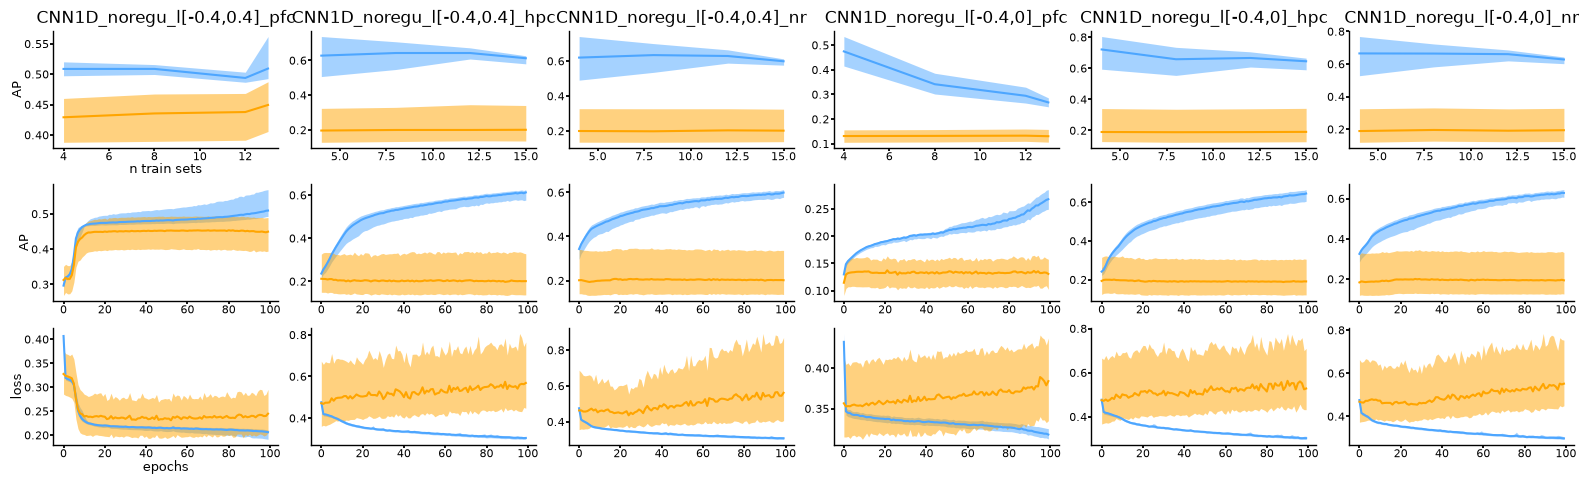

In [6]:
names = ['CNN1D_noregu_l[-0.4,0.4]_pfc','CNN1D_noregu_l[-0.4,0.4]_hpc','CNN1D_noregu_l[-0.4,0.4]_nr',
         'CNN1D_noregu_l[-0.4,0]_pfc','CNN1D_noregu_l[-0.4,0]_hpc','CNN1D_noregu_l[-0.4,0]_nr']
fig, ax = fma.plotting.makeFigure(n=(3,len(names)),size=(40,12))
if ax.ndim == 1: ax = ax.reshape((-1,1))
for i, name in enumerate(names):
        res = joblib.load(froot / f'{name}.joblib')

        fma.plotting.semPlot(res["train_sizes"],res["train_scores"][:,:,-1],color='#4da6ff',ax=ax[0,i])
        fma.plotting.semPlot(res["train_sizes"],res["test_scores"][:,:,-1],color='orange',ax=ax[0,i])

        fma.plotting.semPlot(range(res["train_scores"].shape[-1]),res["train_scores"][:,-1,:],color='#4da6ff',ax=ax[1,i])
        fma.plotting.semPlot(range(res["test_scores"].shape[-1]),res["test_scores"][:,-1,:],color='orange',ax=ax[1,i])

        fma.plotting.semPlot(range(res["train_losses"].shape[1]),res["train_losses"],color='#4da6ff',ax=ax[2,i])
        fma.plotting.semPlot(range(res["val_losses"].shape[1]),res["val_losses"],color='orange',ax=ax[2,i])

        ax[0,i].set(title=name)
ax[0,0].set(xlabel='n train sets',ylabel='AP'), ax[1,0].set(ylabel='AP'), ax[2,0].set(xlabel='epochs',ylabel='loss');